In [4]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# Generate data

from scipy.spatial.transform import Rotation

m = 60
X = np.zeros((m, 3))  # initialize 3D dataset
np.random.seed(42)
angles = (np.random.rand(m) ** 3 + 0.5) * 2 * np.pi  # uneven distribution
X[:, 0], X[:, 1] = np.cos(angles), np.sin(angles) * 0.5  # oval
X += 0.28 * np.random.randn(m, 3)  # add more noise
X = Rotation.from_rotvec([np.pi / 29, -np.pi / 20, np.pi / 4]).apply(X)
X += [0.2, 0, 0.2]  # shift a bit

In [3]:
X[:5]

array([[-0.47562927, -1.18002627, -0.18665138],
       [-0.32908278,  0.18101846, -0.32767249],
       [ 1.1241412 ,  0.33792292,  0.15481443],
       [ 0.28072425, -0.21472162,  0.43963185],
       [-0.59903727, -0.94120105,  0.06412454]])

# PCA

In [5]:
from sklearn.decomposition import PCA

In [4]:
pca = PCA(n_components=2)
X2D = pca.fit_transform(X)

In [5]:
pca.components_

array([[ 0.67857588,  0.70073508,  0.22023881],
       [ 0.72817329, -0.6811147 , -0.07646185]])

In [6]:
pca.explained_variance_ratio_

array([0.7578477 , 0.15186921])

The first dimension explains explain 76% of variance and the 2nd component explains remaning. 

In [7]:
1 - pca.explained_variance_ratio_.sum()

np.float64(0.09028309326742034)

After doing pca we lost 9% of variance

# Choosing the Right number of dimensions

In [8]:
from sklearn.datasets import fetch_openml

mnist = fetch_openml('mnist_784', as_frame=False, parser="auto")
X_train, y_train = mnist.data[:60_000], mnist.target[:60_000]
X_test, y_test = mnist.data[60_000:], mnist.target[60_000:]

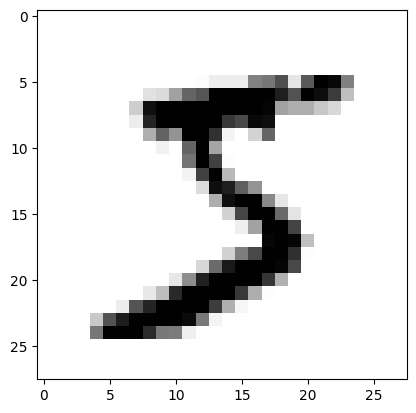

In [12]:
plt.imshow(X_train[0].reshape(28,28),cmap="binary")
plt.show()

In [13]:
pca = PCA()
pca.fit_transform(X_train)

array([[ 1.23932589e+02,  3.12674262e+02,  2.45140518e+01, ...,
        -1.31253055e-11, -1.77241648e-11, -6.32155221e-12],
       [ 1.01171838e+03,  2.94857038e+02, -5.96339561e+02, ...,
         1.21275794e-11,  1.34524253e-11,  9.06974573e-12],
       [-5.18496080e+01, -3.92173153e+02,  1.88509749e+02, ...,
        -1.15731173e-11, -1.15118605e-11, -1.04263941e-11],
       ...,
       [-1.78053450e+02, -1.60078211e+02,  2.57613082e+02, ...,
        -5.48293269e-12, -5.50833123e-12, -3.56682271e-12],
       [ 1.30606072e+02,  5.59193642e+00, -5.13858674e+02, ...,
        -3.37892827e-11, -3.34045501e-11, -2.20298896e-11],
       [-1.73435952e+02,  2.47188023e+01, -5.56018894e+02, ...,
         2.65594330e-11,  3.35996111e-11,  1.91631094e-11]],
      shape=(60000, 784))

In [14]:
cumsum = np.cumsum(pca.explained_variance_ratio_)
#cumsum

array([0.09704664, 0.16800588, 0.22969677, 0.28359097, 0.33227894,
       0.37540125, 0.40812055, 0.4369595 , 0.4645798 , 0.4881498 ,
       0.5092417 , 0.52947161, 0.54662979, 0.56355091, 0.57933732,
       0.59416685, 0.60741246, 0.62018143, 0.63205406, 0.6435809 ,
       0.65424256, 0.66430969, 0.67384542, 0.68297086, 0.69180491,
       0.7001981 , 0.70832389, 0.71618755, 0.72363488, 0.73054347,
       0.73712441, 0.74360589, 0.74963204, 0.75549786, 0.76119807,
       0.76663435, 0.77169222, 0.7765708 , 0.7813851 , 0.78610776,
       0.79067523, 0.79512359, 0.7993086 , 0.80329076, 0.8071405 ,
       0.81089154, 0.81451162, 0.81802754, 0.82142812, 0.82464686,
       0.82783703, 0.83096508, 0.83392491, 0.83681446, 0.83965576,
       0.84237012, 0.84506533, 0.84765006, 0.85018776, 0.85263557,
       0.85504063, 0.85743326, 0.85973735, 0.86195267, 0.86408988,
       0.86616213, 0.86819256, 0.87016038, 0.87208891, 0.87397523,
       0.875845  , 0.87765583, 0.87943146, 0.88118044, 0.88283

In [15]:
d = np.argmax(cumsum>=0.95)+ 1
d

np.int64(154)

By choosing n_components = 154 we can maintain 95% of variance

In [16]:
# Instead of calculationg maniually we can directly mention 
pca = PCA(n_components=0.95)
X_reduced = pca.fit_transform(X_train)

In [17]:
pca.n_components_

np.int64(154)

In [19]:
pca.explained_variance_ratio_.sum()

np.float64(0.9501960192613035)

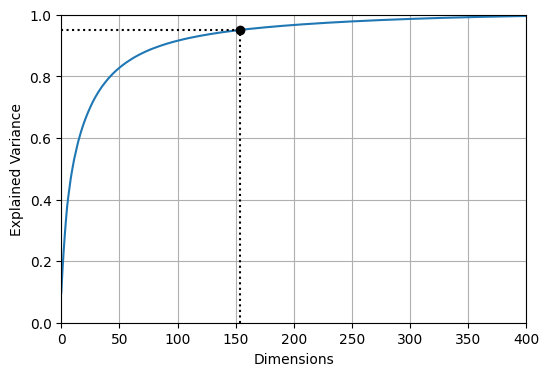

In [21]:
plt.figure(figsize=(6, 4))
plt.plot(cumsum)
plt.axis([0,400,0,1])
plt.xlabel("Dimensions")
plt.ylabel("Explained Variance")
plt.plot([d,d],[0,0.95],"k:")
plt.plot([0,d],[0.95,0.95],"k:")
plt.plot(d,0.95,"ko")
plt.grid(True)
plt.show()

# Hyperparameter tunning

In [22]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV
from sklearn.pipeline import make_pipeline

In [23]:
clf = make_pipeline(
    PCA(random_state=42),
    RandomForestClassifier(random_state=42)
)

In [24]:
param_distrib = {
    "pca__n_components":np.arange(10,80),
    "randomforestclassifier__n_estimators":np.arange(50, 500)
}

In [25]:
rnd_search = RandomizedSearchCV(
    estimator=clf,
    param_distributions=param_distrib,
    n_iter=10,
    cv = 3,
    random_state=42
)

In [26]:
rnd_search.fit(X_train[:1000],y_train[:1000])

,estimator,Pipeline(step...m_state=42))])
,param_distributions,"{'pca__n_components': array([10, 11... 78, 79]), 'randomforestclassifier__n_estimators': array([ 50, ...97, 498, 499])}"
,n_iter,10
,scoring,None
,n_jobs,None
,refit,True
,cv,3
,verbose,0
,pre_dispatch,'2*n_jobs'
,random_state,42
,error_score,nan


In [27]:
rnd_search.best_params_

{'randomforestclassifier__n_estimators': np.int64(475),
 'pca__n_components': np.int64(57)}

In [28]:
rnd_search.best_score_

np.float64(0.8580017142891393)

Above notice that we are reduced a 784-dimensional dataset to just 54 dimensions with good score

# PCA for Compression

In [29]:
pca = PCA(0.95)
X_reduced = pca.fit_transform(X_train,y_train)

In [30]:
# The inverse_transform() method lets us decompress the reduced MNIST dataset back to 784 dimensions:
X_recovered = pca.inverse_transform(X_reduced)

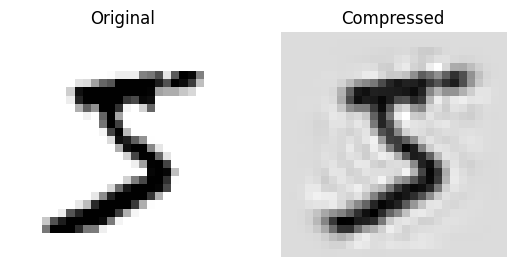

In [32]:
plt.subplot(1,2,1)
plt.imshow(X_train[0].reshape(28,28),cmap="binary")
plt.title("Original")
plt.axis("off")
plt.subplot(1,2,2)
plt.imshow(X_recovered[0].reshape(28,28),cmap="binary")
plt.title("Reconstructed")
plt.axis("off")
plt.show()

You can observe we loss some quality after reconstruction

# Randomized PCA

In [ ]:
pca = PCA(n_components=154,svd_solver="randomized",random_state=42)

By default, svd_solver is actually set to "auto": Scikit-Learn automatically uses the
randomized PCA algorithm if max(m, n) > 500 and n_components is an integer smaller
than 80% of min(m, n), or else it uses the full SVD approach.

# Incremental PCA

incremental PCA (IPCA) algorithms have been developed that
allow you to split the training set into mini-batches and feed these in one
mini-batch at a time. This is useful for large training sets

In [33]:
from sklearn.decomposition import IncrementalPCA

In [34]:
n_batches = 100
inc_pca = IncrementalPCA(n_components=154)
for X_batch in np.array_split(X_train,n_batches):
    inc_pca.partial_fit(X_batch)
X_reduced = inc_pca.transform(X_train)

# Random Projection

As its name suggests, the random projection algorithm projects the data to a
lower-dimensional space using a random linear projection

In [ ]:
from sklearn.random_projection import GaussianRandomProjection

grp = GaussianRandomProjection(eps=0.1,random_state=42)
X = np.random.randn(5_000, 20_000) # generate a fake dataset
X_reduced = grp.fit_transform(X)

Scikit-Learn also provides a second random projection transformer, known as
SparseRandomProjection. It determines the target dimensionality in the same
way, generates a random matrix of the same shape, and performs the
projection identically.it uses much less memory and very faster. \
In summary, random projection is a simple, fast, memory-efficient, and
surprisingly powerful dimensionality reduction algorithm that you should
keep in mind, especially when you deal with high-dimensional datasets.

 # LLM

Locally linear embedding (LLE)⁠ is a nonlinear dimensionality reduction
(NLDR) technique. It is a manifold learning technique that does not rely on
projections, unlike PCA and random projection. In a nutshell, LLE works by
first measuring how each training instance linearly relates to its nearest
neighbors, and then looking for a low-dimensional representation of the
training set where these local relationships are best preserved (more details
shortly). This approach makes it particularly good at unrolling twisted
manifolds, especially when there is not too much noise.

In [1]:
from sklearn.datasets import make_swiss_roll
from sklearn.manifold import LocallyLinearEmbedding

In [2]:
X_swiss, t = make_swiss_roll(n_samples=1000, noise=0.2, random_state=42)
X_swiss[:5],t[:5]

(array([[-3.29677117,  4.26198454,  7.69787682],
        [ 5.95972743, 11.45784273, 12.72625276],
        [ 6.66051523, 18.15820401, -9.84713337],
        [-6.11824123, 15.48364843, -8.30589399],
        [ 6.33443886, 16.41063456, -0.4913301 ]]),
 array([ 8.24234644, 13.67266022, 11.61126935, 10.35461227,  6.18283002]))

In [6]:
X_swiss.shape

(1000, 3)

In [3]:
lle = LocallyLinearEmbedding(n_components=2,n_neighbors=10,random_state=42)
X_unrolled = lle.fit_transform(X_swiss)

In [7]:
X_unrolled.shape

(1000, 2)

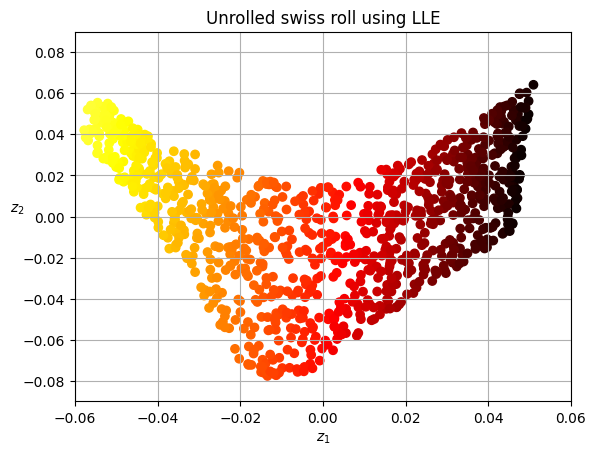

In [10]:
from matplotlib.colors import ListedColormap

darker_hot = ListedColormap(plt.cm.hot(np.linspace(0, 0.8, 256)))

plt.scatter(X_unrolled[:,0],X_unrolled[:,1],c=t,cmap=darker_hot)
plt.xlabel("$z_1$")
plt.ylabel("$z_2$", rotation=0)
plt.axis([-0.060, 0.060, -0.090, 0.090])
plt.grid(True)
plt.title("Unrolled swiss roll using LLE")
plt.show()

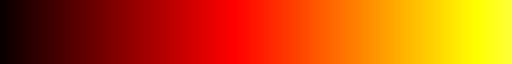

In [11]:
darker_hot

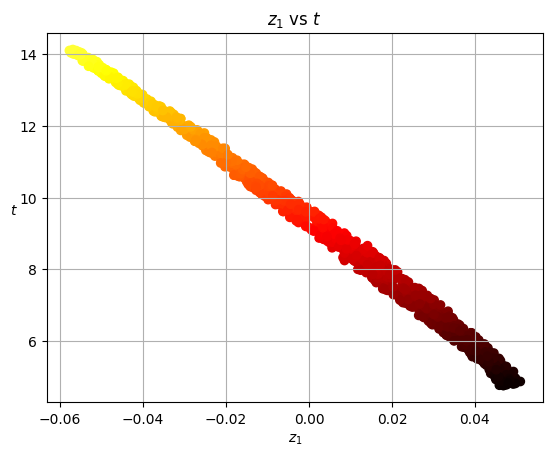

In [12]:
# shows how well correlated z1 is to t: LLE worked fine
plt.title("$z_1$ vs $t$")
plt.scatter(X_unrolled[:, 0], t, c=t, cmap=darker_hot)
plt.xlabel("$z_1$")
plt.ylabel("$t$", rotation=0)
plt.grid(True)
plt.show()

# Other Dimensionality Reduction Techniques

sklearn.manifold.MDS
Multidimensional scaling (MDS) reduces dimensionality while trying to
preserve the distances between the instances. Random projection does
that for high-dimensional data, but it doesn’t work well on low-
dimensional data. \
sklearn.manifold.Isomap
Isomap creates a graph by connecting each instance to its nearest
neighbors, then reduces dimensionality while trying to preserve the
geodesic distances between the instances. The geodesic distance between
two nodes in a graph is the number of nodes on the shortest path between
these nodes. \
sklearn.manifold.TSNE
t-distributed stochastic neighbor embedding (t-SNE) reduces
dimensionality while trying to keep similar instances close and dissimilar
instances apart. It is mostly used for visualization, in particular to
visualize clusters of instances in high-dimensional space. For example, in
the exercises at the end of this chapter you will use t-SNE to visualize a
2D map of the MNIST images. \
sklearn.discriminant_analysis.LinearDiscriminantAnalysis
Linear discriminant analysis (LDA) is a linear classification algorithm
that, during training, learns the most discriminative axes between the
classes. These axes can then be used to define a hyperplane onto which to
project the data. The benefit of this approach is that the projection will
keep classes as far apart as possible, so LDA is a good technique toreduce dimensionality before running another classification algorithm
(unless LDA alone is sufficient).

In [14]:
from sklearn.manifold import MDS

mds = MDS(n_components=2,normalized_stress=False,random_state=42)
X_reduced_mds = mds.fit_transform(X_swiss)

/home/sureshsecond/venv/lib/python3.10/site-packages/sklearn/manifold/_mds.py:677: FutureWarning: The default value of `n_init` will change from 4 to 1 in 1.9.
  warnings.warn(


In [15]:
from sklearn.manifold import TSNE

In [16]:
tsne = TSNE(n_components=2,init='random',learning_rate="auto",random_state=42)
X_reduced_tsne = mds.fit_transform(X_swiss)

/home/sureshsecond/venv/lib/python3.10/site-packages/sklearn/manifold/_mds.py:677: FutureWarning: The default value of `n_init` will change from 4 to 1 in 1.9.
  warnings.warn(


In [17]:
from sklearn.manifold import Isomap
isomap = Isomap(n_components=2)
X_reduced_isomap = mds.fit_transform(X_swiss)

/home/sureshsecond/venv/lib/python3.10/site-packages/sklearn/manifold/_mds.py:677: FutureWarning: The default value of `n_init` will change from 4 to 1 in 1.9.
  warnings.warn(


Note: I think something was wrong. above shoes warnings and below gives same plots. 

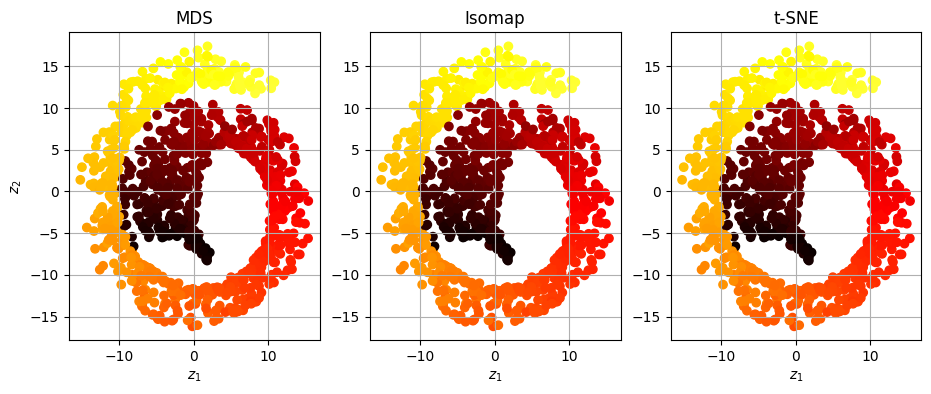

In [18]:
titles = ["MDS", "Isomap", "t-SNE"]
plt.figure(figsize=(11, 4))
for subplot, title, X_reduced in zip([131,132,133],titles,(X_reduced_mds,X_reduced_isomap,X_reduced_tsne)):
    plt.subplot(subplot)
    plt.title(title)
    plt.scatter(X_reduced[:,0],X_reduced[:,1],c=t,cmap=darker_hot)
    plt.xlabel("$z_1$")
    if subplot==131:
        plt.ylabel("$z_2$")
    plt.grid(True)
plt.show()